# Feature Scaling: Standardisation (Z-Score Scaling)

**Standardisation** (or Z-score normalization) is the process of centering a numerical feature around $0$ with a standard deviation of $1$.

For each feature value $x$, standardisation computes:

$$z = \frac{x - \mu}{\sigma}$$

where $\mu$ is the mean of the feature and $\sigma$ is its standard deviation.

---

## Learning Objectives
By the end of this notebook, you will be able to:
1. Understand **why feature magnitude matters** and identify which machine learning algorithms require feature scaling.
2. Recognize algorithms that are **scale-invariant** (e.g., decision trees).
3. Prevent **data leakage** by fitting `StandardScaler` strictly on the training set.
4. Implement standardisation using scikit-learn's `StandardScaler` with pandas DataFrame output.
5. Visually and statistically verify that standardisation preserves the original distribution shape while adjusting center and scale.

---
## 1. Why Feature Scale Matters in Machine Learning

### 1. Distance-Based Algorithms
- **KNN, K-Means, Hierarchical Clustering, SVM**:
  - Distance metrics (e.g., Euclidean distance $d = \sqrt{\sum(x_i - y_i)^2}$) are dominated by features with large numerical magnitudes.
  - A feature with values in the thousands (like `Income`) will completely overshadow a feature with values in single digits (like `YearsOfEducation`).

### 2. Gradient Descent Optimization
- **Linear Regression, Logistic Regression, Neural Networks**:
  - When features have wildly different scales, the loss surface forms elongated, elliptical contours.
  - Gradient descent bounces and oscillates, requiring tiny learning rates and many more epochs to converge. Standardisation spherizes the loss surface, enabling faster and smoother convergence.

### 3. Regularization ($L_1$ Lasso, $L_2$ Ridge, ElasticNet)
- Regularization penalties $\lambda \sum |\beta_j|$ or $\lambda \sum \beta_j^2$ treat all coefficients equally. If features are on different scales, coefficients are artificially sized, causing unfair shrinkage.

### 4. What about Tree-Based Models?
- **Decision Trees, Random Forests, Gradient Boosted Trees (XGBoost, LightGBM, CatBoost)**:
  - **Scale-Invariant**: Trees evaluate one feature at a time and search for monotonic split points (`Feature > Threshold`). Rescaling features does not change the rank ordering of samples and has zero effect on tree splits!

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Matplotlib styling
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['font.size'] = 10

---
## 2. Loading Data & Splitting Train/Test Sets

We use the California Housing dataset. Notice the vast differences in feature scales (e.g. `Population` in thousands vs. `AveRooms` around 5).

> **Data Leakage Rule**: We must split our dataset into train and test sets **before** computing the mean $\mu$ and standard deviation $\sigma$!

In [2]:
# Load dataset
housing = fetch_california_housing(as_frame=True)
data = housing.frame

# Inspect the vastly different magnitudes
summary_stats = data.describe().loc[['mean', 'std', 'min', 'max']].round(2)
print("Original Summary Statistics (Note the huge variation in ranges):")
summary_stats

Original Summary Statistics (Note the huge variation in ranges):


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


In [3]:
# Separate predictors and target
X = data.drop("MedHouseVal", axis=1)
y = data["MedHouseVal"]

# Train/test split (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")

X_train shape: (14448, 8)
X_test shape:  (6192, 8)


---
## 3. Implementing Standardisation with Scikit-Learn

We use scikit-learn's `StandardScaler`.

By configuring `.set_output(transform="pandas")`, `StandardScaler` outputs clean pandas DataFrames retaining all column names and index labels.

In [4]:
# Initialize StandardScaler with pandas output
scaler = StandardScaler()
scaler.set_output(transform="pandas")

# Fit strictly on X_train (learns mean and standard deviation)
scaler.fit(X_train)

# Transform both train and test sets
X_train_scaled = scaler.transform(X_train)
X_test_scaled  = scaler.transform(X_test)

X_train_scaled.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
1989,-1.000304,1.856210,-1.146823,-0.871975,-1.071870,0.259828,0.513964,-0.111314
256,-0.849386,1.141712,-0.765855,0.197335,-0.512516,-0.003271,0.999935,-1.317384
7887,1.286205,-0.922393,0.461027,-0.015158,-0.033194,0.112104,-0.822456,0.760844
4581,-1.135200,-0.922393,-1.270100,0.223585,1.414342,0.001526,-0.733673,0.641234
1993,-0.870432,1.697432,-0.350004,0.147772,-0.712596,0.085648,0.513964,-0.121281


---
## 4. Inspecting the Learned Parameters

The fitted `StandardScaler` stores the parameters learned from `X_train`:
- `scaler.mean_`: Feature means ($\mu$).
- `scaler.scale_`: Feature standard deviations ($\sigma$).

In [5]:
# Create a DataFrame of learned parameters
learned_params = pd.DataFrame({
    'Feature': X_train.columns,
    'Learned Mean (mu)': scaler.mean_,
    'Learned Std (sigma)': scaler.scale_
}).set_index('Feature')

learned_params.round(3)

,Learned Mean (mu),Learned Std (sigma)
Feature,,
MedInc,3.867,1.891
HouseAge,28.619,12.596
AveRooms,5.423,2.288
AveBedrms,1.095,0.453
Population,1425.157,1149.540
AveOccup,3.041,6.868
Latitude,35.630,2.140
Longitude,-119.567,2.007


---
## 5. Statistical Verification of Scaled Data

Let's verify that for `X_train_scaled`:
- The mean of each feature is centered at **$0.0$**.
- The standard deviation of each feature is scaled to **$1.0$**.

In [6]:
# Verify statistics on X_train_scaled
scaled_stats = pd.DataFrame({
    'Scaled Mean (approx 0)': X_train_scaled.mean(),
    'Scaled Std (approx 1)':  X_train_scaled.std(ddof=0)
})

scaled_stats.round(4)

,Scaled Mean (approx 0),Scaled Std (approx 1)
MedInc,0.0,1.0
HouseAge,-0.0,1.0
AveRooms,-0.0,1.0
AveBedrms,0.0,1.0
Population,-0.0,1.0
AveOccup,0.0,1.0
Latitude,0.0,1.0
Longitude,0.0,1.0


Notice on `X_test_scaled`: because the test set contains genuinely unseen data, its mean and std will be *very close* to 0 and 1, but not identically 0 and 1. This is normal and expected!

In [7]:
# Test set statistics under training parameters
test_scaled_stats = pd.DataFrame({
    'X_test Mean': X_test_scaled.mean(),
    'X_test Std':  X_test_scaled.std(ddof=0)
})

test_scaled_stats.round(4)

,X_test Mean,X_test Std
MedInc,0.0071,1.0152
HouseAge,0.0055,0.9971
AveRooms,0.0082,1.2513
AveBedrms,0.0140,1.1484
Population,0.0009,0.9495
AveOccup,0.0146,2.2998
Latitude,0.0028,0.9935
Longitude,-0.0051,0.9949


---
## 6. Visualizing the Impact: Preserving Distribution Shape

> ### 💡 Critical Concept:
> Standardisation **centers and rescales** the data, but **DOES NOT alter the underlying distribution shape**!
> A skewed distribution remains skewed; a bimodal distribution remains bimodal. It does not convert non-normal data into a normal (Gaussian) distribution.

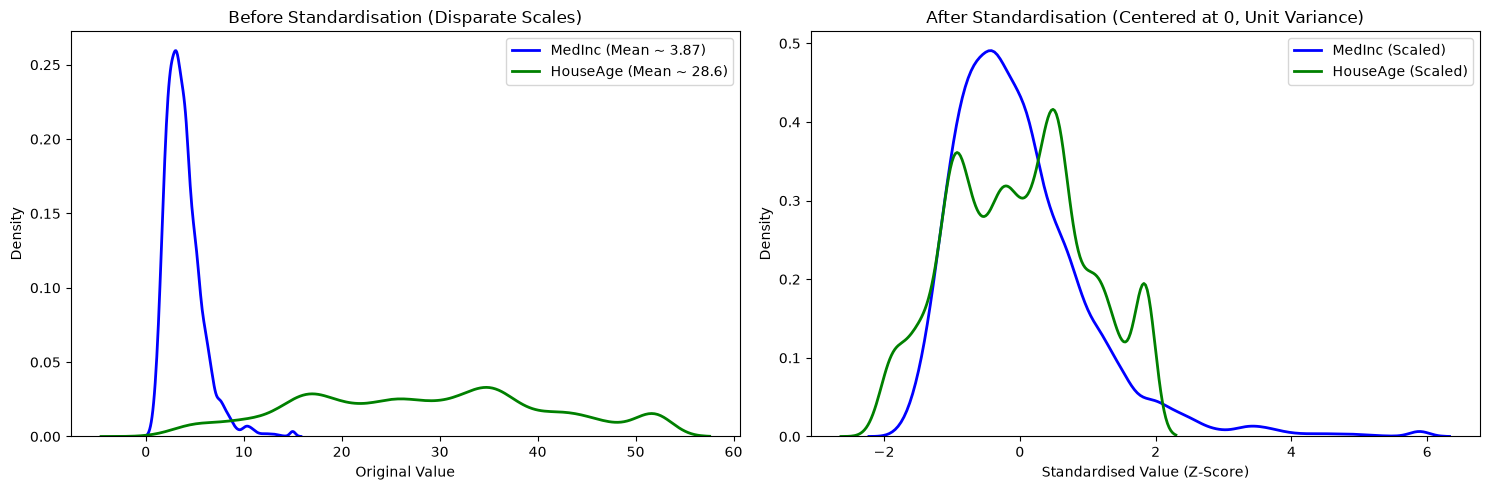

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Before scaling: MedInc and HouseAge on original scales
sns.kdeplot(X_train['MedInc'], ax=ax1, color='blue', label='MedInc (Mean ~ 3.87)', lw=2)
sns.kdeplot(X_train['HouseAge'], ax=ax1, color='green', label='HouseAge (Mean ~ 28.6)', lw=2)
ax1.set_title('Before Standardisation (Disparate Scales)')
ax1.set_xlabel('Original Value')
ax1.legend()

# After scaling: Both centered at 0 with std 1
sns.kdeplot(X_train_scaled['MedInc'], ax=ax2, color='blue', label='MedInc (Scaled)', lw=2)
sns.kdeplot(X_train_scaled['HouseAge'], ax=ax2, color='green', label='HouseAge (Scaled)', lw=2)
ax2.set_title('After Standardisation (Centered at 0, Unit Variance)')
ax2.set_xlabel('Standardised Value (Z-Score)')
ax2.legend()

plt.tight_layout()
plt.show()

---
## 7. Summary & Best Practices Checklist

| Consideration | Recommendation |
| :--- | :--- |
| **When to Use** | Always for **linear models**, **neural networks**, **logistic regression**, **KNN**, **SVM**, and **PCA**. |
| **When Not Needed** | **Decision trees**, **Random Forests**, and **gradient boosting** (scale-invariant). |
| **Data Leakage** | `scaler.fit()` on `X_train` only; use `scaler.transform()` on `X_train` and `X_test`. |
| **Effect on Outliers** | Does not clip outliers. Outliers are simply rescaled into large z-scores ($|z| > 3$). |
| **Distribution Shape** | Preserves relative distances and skewness. Does not make non-normal distributions Gaussian. |
